<a href="https://colab.research.google.com/github/purshottamkumarr/Deep-Learning-learning-project/blob/main/Yolo11_Objection_Detection_on_Custom_Datasets.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!nvidia-smi

Mon Oct 19 16:06:09 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
!pip install ultralytics roboflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 73.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 35.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 126.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 12.1 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.2
    Uninstalling typer-0.27.2:
      Successfully uninstalled typer-0.27.2


In [3]:
import ultralytics
ultralytics.checks()

Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 42.4/112.6 GB disk)


In [4]:
from roboflow import Roboflow
rf = Roboflow(api_key="sjRqMz2lrvHgQuIVwUHh")

In [5]:
workspace = "roboflow-100"
project = "vehicles-q0x2v"
Version_Number = 1


project = rf.workspace(workspace).project(project)
version = project.version(Version_Number)
dataset = version.download("yolov11")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to vehicles-1 in yolov11:: 100%|██████████| 8128/8128 [00:01<00:00, 7130.52it/s]


In [6]:
## path Of the dataset

dataset_path_yaml = "/content/vehicles-1/data.yaml"

print("The dataset of yaml file are ",dataset_path_yaml)

The dataset of yaml file are  /content/vehicles-1/data.yaml


In [7]:
## View the dataset of the yaml file
!cat $dataset_path_yaml

train: ../train/images
val: ../valid/images
test: ../test/images

nc: 12
names: ['big bus', 'big truck', 'bus-l-', 'bus-s-', 'car', 'mid truck', 'small bus', 'small truck', 'truck-l-', 'truck-m-', 'truck-s-', 'truck-xl-']

roboflow:
  workspace: roboflow-100
  project: vehicles-q0x2v
  version: 1
  license: CC BY 4.0
  url: https://universe.roboflow.com/roboflow-100/vehicles-q0x2v/dataset/1

In [9]:
from ultralytics import YOLO

# Load a COCO-pretrained YOLO11n model

model = YOLO("yolo11n.pt")

results = model.train(data=dataset_path_yaml,epochs=1,imgsz=640,batch=16)

print("Training Completed.check/content/runs/detect/train for weights and results")

Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/vehicles-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2, nbs=64, nms=None, opset=None, optimize=False, optimi

In [10]:
import os

for items in os.listdir("/content"):
  print(items)

.config
vehicles-1
weights
yolo11n.pt
runs


In [11]:
val_result = model.val(data = dataset_path_yaml)

print("The Validation Is Successful")

Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,599,724 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1925.2±563.8 MB/s, size: 57.0 KB)
val: Scanning /content/vehicles-1/valid/labels.cache... 966 images, 3 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 966/966 270.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 61/61 4.9it/s 12.4s
                   all        966      13450      0.378      0.333      0.212      0.125
               big bus        210        273      0.266      0.432      0.261      0.181
             big truck        404       1162      0.385      0.496      0.401      0.213
                bus-l-          8          8          0          0    0.00123   0.000491
                bus-s-         12         12          1          0    0.00188    0.00125
                   car        927       


image 1/1 /content/vehicles-1/valid/images/adit_mp4-1004_jpg.rf.2b982369107d16089e284c84535bdea7.jpg: 640x640 1 big truck, 17 cars, 1 truck-l-, 2 truck-m-s, 1 truck-s-, 1 truck-xl-, 11.1ms
Speed: 1.4ms preprocess, 11.1ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict
Predication Saved To the /content/runs/detect/predict
Displaying the predicated Images /content/runs/detect/predict/adit_mp4-1004_jpg.rf.2b982369107d16089e284c84535bdea7.jpg


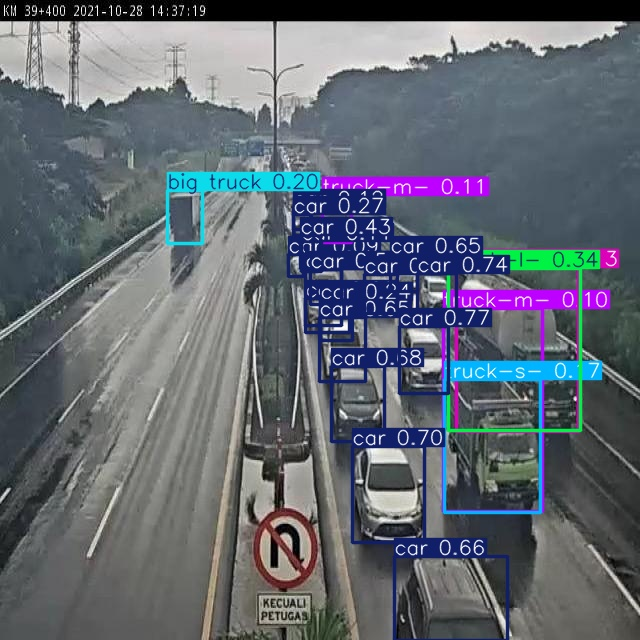

In [15]:
import cv2
import os
from google.colab.patches import cv2_imshow

def show_images(image_path):
  image = cv2.imread(image_path)
  if image is None:
    print("The Image is not Not Found",image_path)
    return
  cv2_imshow(image)

test_images = "/content/vehicles-1/valid/images/adit_mp4-1004_jpg.rf.2b982369107d16089e284c84535bdea7.jpg"

predication_result = model.predict(source=test_images,save=True,conf=0.05)

save_dir = predication_result[0].save_dir
print("Predication Saved To the",save_dir)

saved_images = [os.path.join(save_dir,image)for image in os.listdir(save_dir) if image.endswith(".jpg")]

if len(saved_images)==0:
  print("No Predication Found in",save_dir)
  print("Content of the Directory",os.listdir(save_dir))
else:
  print("Displaying the predicated Images",saved_images[0])
  show_images(saved_images[0])